# 06 — Benchmark DSP envelope: Hybrid và Hilbert Block so với FFT-Hilbert Offline

**Tham chiếu duy nhất:** FFT Hilbert toàn file trên PC (`hilbert_offline`). Đây là tham chiếu số học ngoại tuyến, không phải ground truth tuyệt đối.

**Hai phép so sánh độc lập:**
1. **Hybrid vs FFT Hilbert Offline**.
2. **Hilbert Block 2048 (mô phỏng Hilbert-MCU) vs FFT Hilbert Offline**.

Không tính một phép so sánh trực tiếp Hybrid vs Hilbert Block. Mỗi ứng viên được đánh giá với cùng tham chiếu offline bằng cùng `BenchConfig`.

**A. Fidelity:** Pearson ρ và NRMSE sau căn chỉnh; relative lag trước căn chỉnh; Peak Amplitude Error (dB) trên phổ chưa chuẩn hóa; Envelope Spectrum Error với `ref_norm` và `own_norm`.

**B. Robustness:** tổng hợp từ Fidelity theo Normal/IR/OR/Ball và tải 0–3 HP, riêng từng ứng viên.

**Hình minh họa:** notebook 04 đã trình bày từng phương pháp riêng. Ở notebook 06 chỉ vẽ chồng ba envelope trên cùng một hình và chồng ba phổ envelope trên cùng một hình.

**Không thuộc notebook này:** Macro-F1/Accuracy (notebook ML), DSP cycles/Flash/SRAM (firmware STM32F4), AWGN/đổi BPF.

**Cách chạy:** đặt notebook ở thư mục gốc dự án (cạnh `src/` và `outputs/`), chọn *Restart Kernel and Run All*. Chỉ coi benchmark hoàn tất khi `06_dsp_benchmark_errors.csv` rỗng.

In [1]:
from pathlib import Path
import json, re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src import io_utils, dsp, config as cfg
from src import dsp_benchmark as bm

# ---------- ???ng d?n & ??u v?o ----------
# T?m g?c d? ?n t? working directory ?? notebook ch?y ???c c? khi m?
# t? th? m?c g?c l?n t? notebooks/giai_doan_1_tien_xu_ly.
cwd = Path.cwd().resolve()
REPO_ROOT = next((p for p in (cwd, *cwd.parents) if (p / 'src').is_dir() and (p / 'notebooks').is_dir()), None)
if REPO_ROOT is None:
    raise FileNotFoundError(f'Kh?ng t?m th?y th? m?c g?c d? ?n (c?n c? src/ v? notebooks/) t? {cwd}')
STAGE_DIR = REPO_ROOT / 'notebooks' / 'giai_doan_1_tien_xu_ly'
OUT = STAGE_DIR / 'outputs'; TABLES = OUT / 'tables'; FIGS = OUT / 'figures'
TABLES.mkdir(parents=True, exist_ok=True); FIGS.mkdir(parents=True, exist_ok=True)
MANIFEST_PATH = TABLES / 'manifest_clean.csv'
CONFIG_PATH = TABLES / 'bandpass_config.json'
if not MANIFEST_PATH.exists():
    raise FileNotFoundError(f'Kh?ng t?m th?y {MANIFEST_PATH}. H?y ch?y notebook 01_build_manifest v? 05_build_feature_table tr??c.')
if not CONFIG_PATH.exists():
    raise FileNotFoundError(f'Kh?ng t?m th?y {CONFIG_PATH}. H?y ch?y notebook 03_choose_bandpass t? ??u ?? t?o c?u h?nh bandpass, r?i ch?y l?i notebook 06.')

manifest = pd.read_csv(MANIFEST_PATH)
miss = [c for c in ['file_path', 'label', 'load_hp', 'resolved_sample_rate_hz'] if c not in manifest]
if miss:
    raise ValueError(f'Manifest thiếu cột: {miss}')
if manifest.empty or manifest['file_path'].isna().any():
    raise ValueError('Manifest rỗng hoặc có file_path rỗng.')
manifest = manifest.sort_values(['label', 'file_path']).reset_index(drop=True)

with open(CONFIG_PATH, encoding='utf-8') as f:
    CONF = json.load(f)
BAND_HZ = tuple(float(v) for v in CONF['band_hz'])
LP_CUTOFF_HZ = float(CONF['lp_cutoff_hz'])
BPF_ORDER = int(CONF.get('bandpass_order', dsp.BENCHMARK_BANDPASS_ORDER))
LP_ORDER = int(CONF.get('lowpass_order', dsp.BENCHMARK_LOWPASS_ORDER))
WARMUP = int(CONF.get('warmup_samples', 0))

# ---------- cấu hình Hilbert Block khớp bản mô phỏng MCU ----------
HILBERT_BLOCK_SIZE = int(getattr(dsp, 'HILBERT_BLOCK_SIZE', 2048))
HILBERT_BLOCK_FLOAT32 = True
if HILBERT_BLOCK_SIZE != 2048:
    raise ValueError(f'Benchmark hiện khóa Hilbert Block N=2048, nhưng dsp.py đang đặt N={HILBERT_BLOCK_SIZE}.')

# ---------- tham số benchmark (một nơi duy nhất) ----------
BC = bm.BenchConfig(
    fs=float(CONF['fs_hz']), warmup=WARMUP,
    edge_trim=int(CONF.get('hilbert_edge_trim_samples', 0)),
    max_lag_samples=100, fmax_hz=500.0,
    search_width_hz=3.0, floor_half_width_hz=15.0,
    peak_snr_min=3.0, rel_peak_floor=1e-3,
    max_freq_resolution_hz=1.0, min_bins_per_target=10.0,
    harmonics=(1, 2, 3), fault_names=('BPFO', 'BPFI', 'BSF', 'FTF'),
)

# Chỉ có HAI ứng viên. FFT Hilbert Offline là tham chiếu chung.
CANDIDATE_METHODS = {
    'Hybrid': {'key': 'hybrid', 'color': 'tab:green'},
    'Hilbert-MCU': {'key': 'hilbert_block', 'color': 'tab:blue'},
}
REFERENCE_METHOD = 'FFT Hilbert Offline'

print(f'{len(manifest)} file | BPF {BAND_HZ[0]:g}–{BAND_HZ[1]:g} Hz (bậc {BPF_ORDER}) | '
      f'LPF {LP_CUTOFF_HZ:g} Hz (bậc {LP_ORDER}) | fs {BC.fs:g} Hz')
print(f'Hilbert Block N={HILBERT_BLOCK_SIZE}, float32={HILBERT_BLOCK_FLOAT32} | '
      f'warm-up={BC.warmup} | trim cuối={BC.edge_trim} | lag ±{BC.max_lag_samples} mẫu')
print('Các phép so sánh: Hybrid vs FFT Hilbert Offline; Hilbert-MCU vs FFT Hilbert Offline.')

40 file | BPF 2300–3800 Hz (bậc 4) | LPF 750 Hz (bậc 2) | fs 12000 Hz
Hilbert Block N=2048, float32=True | warm-up=2048 | trim cuối=0 | lag ±100 mẫu
Các phép so sánh: Hybrid vs FFT Hilbert Offline; Hilbert-MCU vs FFT Hilbert Offline.


## 1. Đọc tín hiệu và tạo ba envelope

Tạo ba envelope trên cùng tín hiệu:
- `hybrid`: phương pháp đề xuất.
- `hilbert_offline`: FFT Hilbert toàn file, tham chiếu chung.
- `hilbert_block`: FFT Hilbert từng block 2048 mẫu, mô phỏng cách triển khai dự kiến trên MCU.

Notebook chỉ đánh giá hai ứng viên (`hybrid`, `hilbert_block`) so với `hilbert_offline`.

In [2]:
def load_signal(row):
    x = np.asarray(io_utils.load_de_signal_resampled(
        Path(str(row['file_path'])), float(row['resolved_sample_rate_hz']), BC.fs
    ), dtype=np.float64).reshape(-1)
    if not np.isfinite(x).all():
        raise ValueError('Tín hiệu có NaN/Inf.')
    if len(x) <= BC.warmup + BC.edge_trim + BC.max_lag_samples + 10:
        raise ValueError('File quá ngắn sau warm-up/trim.')
    return x


def compute_envelopes(x):
    """Ba nhánh dùng chung BPF/LPF và quy tắc DC; không chèn trễ nhân tạo."""
    common_kw = dict(
        band=BAND_HZ,
        bandpass_order=BPF_ORDER,
        lp_cutoff=LP_CUTOFF_HZ,
        lowpass_order=LP_ORDER,
        remove_dc=False,
    )

    envs = {
        'hybrid': dsp.hybrid_envelope(x, BC.fs, **common_kw),
        'hilbert_offline': dsp.hilbert_envelope(
            x, BC.fs, align_delay=False, **common_kw
        ),
        'hilbert_block': dsp.hilbert_block_envelope(
            x, BC.fs,
            block_size=HILBERT_BLOCK_SIZE,
            float32=HILBERT_BLOCK_FLOAT32,
            align_delay=False,
            **common_kw,
        ),
    }

    envs = {k: np.asarray(v, dtype=np.float64).reshape(-1) for k, v in envs.items()}
    for name, values in envs.items():
        if len(values) != len(x) or not np.isfinite(values).all():
            raise ValueError(f'{name}: envelope không hợp lệ hoặc sai chiều dài.')
    return envs


def get_rpm(row):
    for col in ('rpm', 'rpm_from_file'):
        v = row.get(col)
        if v is not None and not pd.isna(v) and np.isfinite(float(v)) and float(v) > 0:
            return float(v), col
    load = row.get('load_hp')
    if load is None or pd.isna(load) or int(load) not in cfg.NOMINAL_RPM_BY_LOAD:
        raise ValueError('Không có RPM hợp lệ và không có RPM danh định theo tải.')
    return float(cfg.NOMINAL_RPM_BY_LOAD[int(load)]), f'nominal_by_load_{int(load)}HP'


def make_case(idx, row):
    label = str(row['label'])
    fn = Path(str(row['file_path']).replace('\\', '/')).name
    ftype = bm.classify_fault_type(label, fn, row)
    rpm, rpm_src = get_rpm(row)
    opt_int = lambda v: None if v is None or pd.isna(v) else int(v)
    safe = lambda s: re.sub(r'[^A-Za-z0-9._-]+', '_', s)
    return {
        'case_id': f'{idx:04d}_{safe(label)}_{safe(Path(fn).stem)}',
        'file_path': str(row['file_path']), 'filename': fn, 'label': label,
        'fault_type': ftype, 'record_group': 'Normal' if ftype == 'Normal' else 'Fault',
        'load_hp': opt_int(row.get('load_hp')),
        'fault_diameter_mils': opt_int(row.get('fault_diameter_mils')),
        'source_fs_hz': float(row['resolved_sample_rate_hz']),
        'rpm': rpm, 'rpm_source': rpm_src,
        'faults': {
            str(k): float(v)
            for k, v in cfg.bearing_fault_frequencies(rpm).items()
            if np.isfinite(float(v))
        },
    }


# Kiểm tra phân loại nhãn -> loại lỗi trước khi chạy
_ft = manifest.apply(
    lambda r: bm.classify_fault_type(
        r['label'], Path(str(r['file_path']).replace('\\', '/')).name, r
    ), axis=1
)
display(pd.crosstab(manifest['label'], _ft).rename_axis(index='label', columns='fault_type'))
if (_ft == 'Unknown').any():
    print('CẢNH BÁO: có nhãn không phân loại được → thêm metadata fault_type hoặc sửa classify_fault_type().')

fault_type,Ball,IR,Normal,OR
label,,,,
B,12,0,0,0
IR,0,12,0,0
Normal,0,0,4,0
OR,0,0,0,12


## 2. Chạy hai phép so sánh với cùng tham chiếu FFT Hilbert Offline

Mỗi file chỉ tạo ba envelope một lần. Sau đó chạy `evaluate_candidates()` với hai ứng viên:
- `Hybrid`.
- `Hilbert-MCU` (Hilbert Block 2048, float32).

Cả hai đều được so sánh độc lập với `FFT Hilbert Offline`. Không có phép so sánh Hybrid trực tiếp với Hilbert-MCU.

In [3]:
wave_rows, peak_rows, error_rows = [], [], []

for idx, row in manifest.iterrows():
    try:
        case = make_case(int(idx), row)
        envs = compute_envelopes(load_signal(row))

        candidates = {
            'Hybrid': envs['hybrid'],
            'Hilbert-MCU': envs['hilbert_block'],
        }
        results = bm.evaluate_candidates(
            case=case,
            candidates=candidates,
            reference_env=envs['hilbert_offline'],
            cfg=BC,
            decimate=dsp.decimate_envelope,
            reference_name=REFERENCE_METHOD,
        )

        for method_name, result in results.items():
            wave_rows.append(result['wave'])
            peak_rows.extend(result['peaks'])

    except Exception as exc:
        error_rows.append({
            'manifest_row_index': int(idx),
            'file_path': str(row['file_path']),
            'label': str(row.get('label', '')),
            'error_type': type(exc).__name__,
            'error_message': str(exc),
        })
        print(f'[LỖI] {row["file_path"]}: {type(exc).__name__}: {exc}')

    if (idx + 1) % 10 == 0 or idx + 1 == len(manifest):
        print(f'{idx + 1}/{len(manifest)}')

wave = pd.DataFrame(wave_rows)
peaks = pd.DataFrame(peak_rows)
errors = pd.DataFrame(
    error_rows,
    columns=['manifest_row_index', 'file_path', 'label', 'error_type', 'error_message'],
)
enc = 'utf-8-sig'
errors.to_csv(TABLES / '06_dsp_benchmark_errors.csv', index=False, encoding=enc)

n_ok = int(wave['case_id'].nunique()) if len(wave) else 0
print(f'\nHoàn tất: {n_ok}/{len(manifest)} file thành công, {len(errors)} lỗi.')
if wave.empty:
    raise RuntimeError('Không file nào chạy thành công — xem 06_dsp_benchmark_errors.csv.')

expected_methods = {'Hybrid', 'Hilbert-MCU'}
actual_methods = set(wave['method'].dropna().unique())
if actual_methods != expected_methods:
    raise RuntimeError(f'Benchmark thiếu phương pháp: expected={expected_methods}, actual={actual_methods}')

10/40
20/40
30/40
40/40

Hoàn tất: 40/40 file thành công, 0 lỗi.


## 3. Tổng hợp và xuất CSV

- **Fidelity:** tổng hợp riêng theo `method`, với cùng tham chiếu FFT Hilbert Offline.
- **Peak Amplitude Error:** chi tiết theo file và tổng hợp riêng từng phương pháp.
- **Robustness:** Pearson/NRMSE theo loại tình trạng và tải, riêng từng phương pháp.
- Nhóm không có file vẫn hiện `n_files = 0`.
- Bảng headline chỉ lấy nhóm Fault; bản ghi Normal không có đỉnh lỗi thật.

In [4]:
# ---- Fidelity: tách tổng hợp theo từng ứng viên ----
wave_sum = bm.wave_summary_by_method(wave)

# ---- Peak Amplitude Error: không gộp hai ứng viên vào cùng một nhóm ----
spec_sum = bm.peak_summary(
    peaks,
    ['method', 'record_group', 'fault_type', 'rpm_source', 'fault_component', 'harmonic'],
)
spec_head = bm.peak_summary(
    peaks[peaks['record_group'] == 'Fault'],
    ['method', 'fault_component'],
)

# ---- Robustness: chạy riêng theo method để không gộp nhầm hai ứng viên ----
rob_fault_parts, rob_load_parts = [], []
for method_name in ('Hybrid', 'Hilbert-MCU'):
    method_wave = wave.loc[wave['method'] == method_name].copy()
    if method_wave.empty:
        continue
    rob_fault_parts.append(
        bm.robustness_table(method_wave, 'fault_type', bm.FAULT_TYPE_ORDER, method_name=method_name)
    )
    rob_load_parts.append(
        bm.robustness_table(method_wave, 'load_hp', bm.LOAD_ORDER, method_name=method_name)
    )
rob_fault = pd.concat(rob_fault_parts, ignore_index=True)
rob_load = pd.concat(rob_load_parts, ignore_index=True)

for name, table in (('loại lỗi', rob_fault), ('tải', rob_load)):
    if (table['n_files'] == 0).any():
        print(f'LƯU Ý: có nhóm {name} không có file → xem cột n_files.')

# ---- xuất ----
wave.to_csv(TABLES / '06_waveform_metrics_by_file.csv', index=False, encoding=enc)
wave_sum.to_csv(TABLES / '06_waveform_metrics_summary_by_method.csv', index=False, encoding=enc)
peaks.to_csv(TABLES / '06_fault_spectrum_errors_by_file.csv', index=False, encoding=enc)
spec_sum.to_csv(TABLES / '06_fault_spectrum_error_summary.csv', index=False, encoding=enc)
spec_head.to_csv(TABLES / '06_fault_spectrum_headline.csv', index=False, encoding=enc)
rob_fault.to_csv(TABLES / '06_robustness_by_fault_type.csv', index=False, encoding=enc)
rob_load.to_csv(TABLES / '06_robustness_by_load.csv', index=False, encoding=enc)

params = {
    **BC.as_dict(),
    'band_hz': list(BAND_HZ),
    'lp_cutoff_hz': LP_CUTOFF_HZ,
    'bandpass_order': BPF_ORDER,
    'lowpass_order': LP_ORDER,
    'methods': ['hybrid', 'hilbert_offline', 'hilbert_block'],
    'candidate_methods': ['Hybrid', 'Hilbert-MCU'],
    'reference_method': REFERENCE_METHOD,
    'comparisons': [
        'Hybrid vs FFT Hilbert Offline',
        'Hilbert-MCU (Hilbert Block 2048) vs FFT Hilbert Offline',
    ],
    'hilbert_block_size': HILBERT_BLOCK_SIZE,
    'hilbert_block_float32': HILBERT_BLOCK_FLOAT32,
    'hilbert_block_overlap': 0,
    'hilbert_block_tail_policy': 'zero-pad final partial block to N=2048; retain only valid output samples',
    'hilbert_align_delay': False,
    'remove_dc': False,
    'peak_amplitude_error_db': '20*log10(A_candidate/A_reference); unnormalized Hann spectra, same segment',
    'lag_us': 'lag_samples / fs * 1e6',
    'envspec_nrmse_ref_norm': 'both spectra divided by reference Hilbert peak',
    'envspec_nrmse_own_norm': 'each spectrum divided by own peak',
    'n_files_ok': n_ok,
    'n_files_manifest': int(len(manifest)),
    'n_errors': int(len(errors)),
}
with open(TABLES / '06_benchmark_params.json', 'w', encoding='utf-8') as f:
    json.dump(params, f, indent=2, ensure_ascii=False)

print('=== A. Fidelity: dạng sóng — từng phương pháp so với FFT Hilbert Offline ===')
display(wave_sum.round(4).T)
print('=== A. Peak Amplitude Error (dB) — nhóm Fault, đỉnh hợp lệ ===')
cols = ['method', 'fault_component', 'n_rows', 'n_prominent', 'n_valid_peak',
        'peak_error_db_median_signed', 'abs_peak_error_db_median',
        'abs_peak_error_db_p95', 'note']
display(spec_head[cols].round(3))
print('Lý do đỉnh không hợp lệ (peak_invalid_reason):')
display(pd.crosstab([peaks['method'], peaks['record_group']], peaks['peak_invalid_reason']))
print('=== B. Robustness theo loại tình trạng ==='); display(rob_fault.round(4))
print('=== B. Robustness theo tải ==='); display(rob_load.round(4))

n_nom = int(wave['rpm_source'].astype(str).str.startswith('nominal_by_load_').sum())
print(f'Bản ghi phương pháp dùng RPM danh định: {n_nom}/{len(wave)} (đếm theo method-file).')
if len(errors):
    print('CẢNH BÁO: còn lỗi xử lý file; không dùng kết quả cuối cùng cho báo cáo.')
else:
    print('Không có lỗi xử lý file.')

=== A. Fidelity: dạng sóng — từng phương pháp so với FFT Hilbert Offline ===


,0,1
method,Hybrid,Hilbert-MCU
n_files,40,40
pearson_mean,0.9997,1.0
pearson_std,0.0002,0.0
pearson_min,0.9987,1.0
nrmse_mean,0.0286,0.0034
nrmse_median,0.028,0.0029
nrmse_std,0.0043,0.0012
nrmse_max,0.0378,0.007
lag_samples_abs_median,1.0,0.0


=== A. Peak Amplitude Error (dB) — nhóm Fault, đỉnh hợp lệ ===


,method,fault_component,n_rows,n_prominent,n_valid_peak,peak_error_db_median_signed,abs_peak_error_db_median,abs_peak_error_db_p95,note
0,Hilbert-MCU,BPFI,108,97,97,-0.002,0.003,0.029,
1,Hilbert-MCU,BPFO,108,95,95,-0.002,0.003,0.038,
2,Hilbert-MCU,BSF,108,92,92,-0.001,0.008,0.051,
3,Hilbert-MCU,FTF,108,92,92,-0.000,0.004,0.019,
4,Hybrid,BPFI,108,97,97,0.194,0.194,0.369,
5,Hybrid,BPFO,108,95,95,0.198,0.198,0.379,
6,Hybrid,BSF,108,92,92,0.209,0.209,0.323,
7,Hybrid,FTF,108,92,92,0.217,0.217,0.357,


Lý do đỉnh không hợp lệ (peak_invalid_reason):


peak_invalid_reason        ok  ref_not_prominent
method      record_group                        
Hilbert-MCU Fault         376                 56
            Normal         21                 27
Hybrid      Fault         376                 56
            Normal         21                 27

=== B. Robustness theo loại tình trạng ===


,fault_type,method,n_files,pearson_mean,pearson_std,pearson_min,nrmse_mean,nrmse_median,nrmse_std,nrmse_max,lag_samples_abs_median,lag_us_mean,lag_us_abs_median,envspec_nrmse_ref_norm_mean,envspec_nrmse_own_norm_mean,envspec_pearson_mean
0,Normal,Hybrid,4,0.9992,0.0003,0.9987,0.0281,0.0283,0.0012,0.0292,1.0,83.3333,83.3333,0.0434,0.0304,0.9986
1,IR,Hybrid,12,0.9997,0.0001,0.9996,0.0293,0.0265,0.0056,0.0378,1.0,83.3333,83.3333,0.0286,0.0132,0.9999
2,OR,Hybrid,12,0.9999,0.0001,0.9998,0.0253,0.0261,0.0026,0.0280,1.0,83.3333,83.3333,0.0237,0.0104,0.9999
3,Ball,Hybrid,12,0.9998,0.0000,0.9997,0.0314,0.0305,0.0023,0.0347,1.0,83.3333,83.3333,0.0321,0.0129,0.9999
4,Normal,Hilbert-MCU,4,1.0000,0.0000,1.0000,0.0029,0.0029,0.0003,0.0033,0.0,0.0000,0.0000,0.0040,0.0040,1.0000
5,IR,Hilbert-MCU,12,1.0000,0.0000,1.0000,0.0035,0.0032,0.0015,0.0069,0.0,0.0000,0.0000,0.0030,0.0029,1.0000
6,OR,Hilbert-MCU,12,1.0000,0.0000,1.0000,0.0040,0.0035,0.0014,0.0070,0.0,0.0000,0.0000,0.0032,0.0032,1.0000
7,Ball,Hilbert-MCU,12,1.0000,0.0000,1.0000,0.0028,0.0027,0.0006,0.0041,0.0,0.0000,0.0000,0.0028,0.0028,1.0000


=== B. Robustness theo tải ===


,load_hp,method,n_files,pearson_mean,pearson_std,pearson_min,nrmse_mean,nrmse_median,nrmse_std,nrmse_max,lag_samples_abs_median,lag_us_mean,lag_us_abs_median,envspec_nrmse_ref_norm_mean,envspec_nrmse_own_norm_mean,envspec_pearson_mean
0,0,Hybrid,10,0.9997,0.0003,0.9987,0.0290,0.0280,0.0046,0.0378,1.0,83.3333,83.3333,0.0314,0.0151,0.9996
1,1,Hybrid,10,0.9997,0.0002,0.9993,0.0287,0.0282,0.0043,0.0367,1.0,83.3333,83.3333,0.0296,0.0137,0.9998
2,2,Hybrid,10,0.9997,0.0002,0.9993,0.0285,0.0281,0.0042,0.0362,1.0,83.3333,83.3333,0.0290,0.0128,0.9998
3,3,Hybrid,10,0.9998,0.0002,0.9993,0.0282,0.0279,0.0045,0.0351,1.0,83.3333,83.3333,0.0287,0.0143,0.9998
4,0,Hilbert-MCU,10,1.0000,0.0000,1.0000,0.0040,0.0039,0.0011,0.0058,0.0,0.0000,0.0000,0.0036,0.0036,1.0000
5,1,Hilbert-MCU,10,1.0000,0.0000,1.0000,0.0036,0.0031,0.0014,0.0069,0.0,0.0000,0.0000,0.0035,0.0035,1.0000
6,2,Hilbert-MCU,10,1.0000,0.0000,1.0000,0.0025,0.0024,0.0006,0.0033,0.0,0.0000,0.0000,0.0024,0.0024,1.0000
7,3,Hilbert-MCU,10,1.0000,0.0000,1.0000,0.0034,0.0028,0.0014,0.0070,0.0,0.0000,0.0000,0.0029,0.0029,1.0000


Bản ghi phương pháp dùng RPM danh định: 0/80 (đếm theo method-file).
Không có lỗi xử lý file.


## 4. Hình minh họa một file (không tham gia số liệu)

Chỉ vẽ chồng ba envelope trong cùng một hình (file 04 đã trình bày từng phương pháp riêng):
- Hybrid.
- FFT Hilbert Offline — tham chiếu.
- Hilbert-MCU — Hilbert Block 2048, float32.

Tín hiệu sau BPF được giữ làm nền mờ. Hình phổ cũng chồng ba phổ envelope đã chuẩn hóa theo đỉnh riêng để quan sát hình dạng.

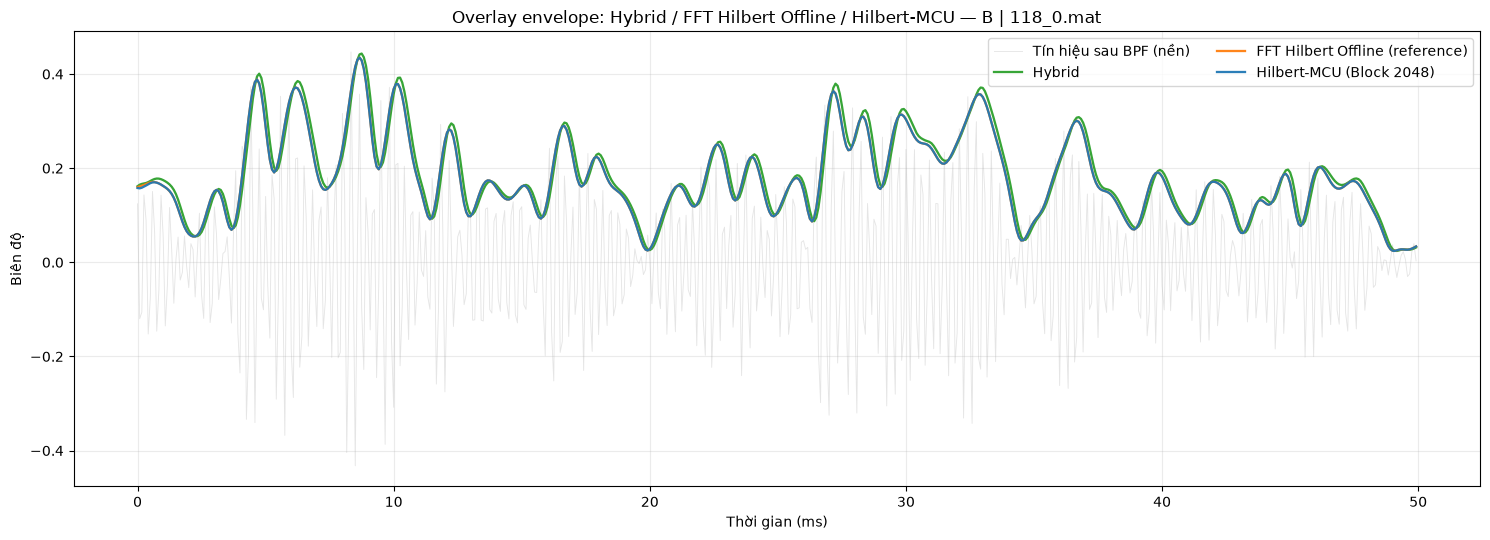

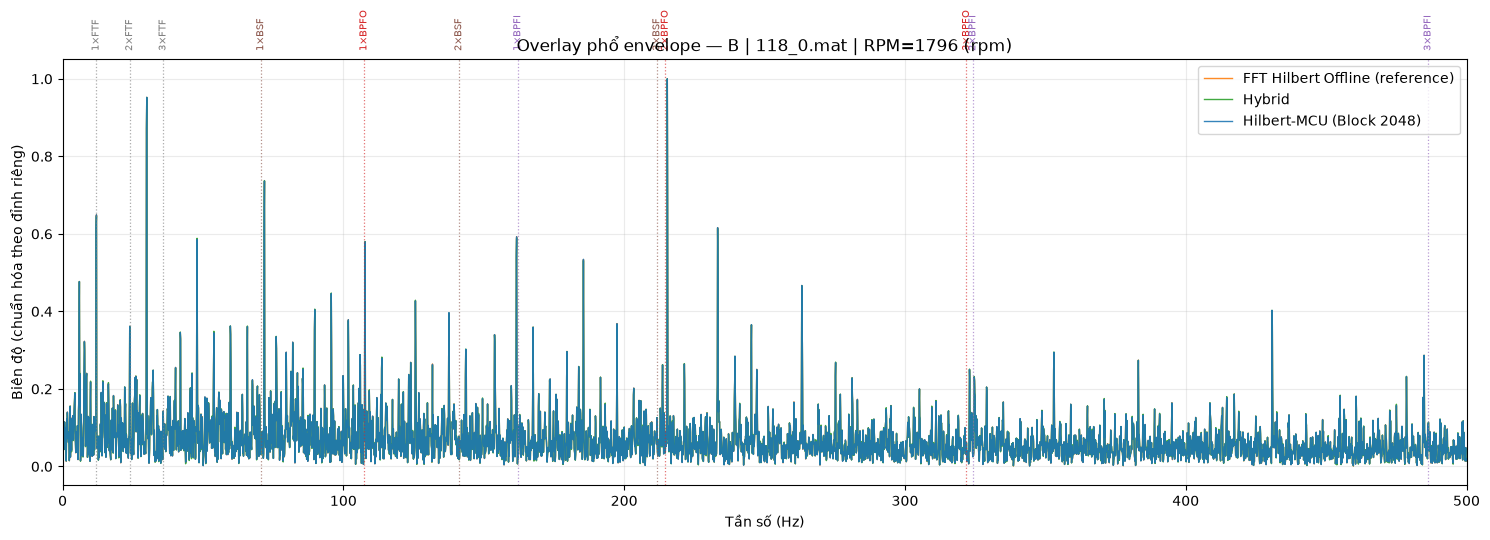

In [5]:
FILE_INDEX = 0          # chỉ ảnh hưởng hình minh họa
SEGMENT_SECONDS = 0.05
if not (0 <= FILE_INDEX < len(manifest)):
    raise IndexError(f'FILE_INDEX phải trong [0, {len(manifest) - 1}]')

row = manifest.iloc[FILE_INDEX]
case = make_case(FILE_INDEX, row)
x = load_signal(row)
envs = compute_envelopes(x)

# Tạo lại đúng hai phép so sánh với cùng tham chiếu để lấy phổ minh họa.
plot_results = bm.evaluate_candidates(
    case=case,
    candidates={
        'Hybrid': envs['hybrid'],
        'Hilbert-MCU': envs['hilbert_block'],
    },
    reference_env=envs['hilbert_offline'],
    cfg=BC,
    decimate=dsp.decimate_envelope,
    reference_name=REFERENCE_METHOD,
)

x_bp = dsp.bandpass_filter(
    x, BC.fs, BAND_HZ[0], BAND_HZ[1], order=BPF_ORDER, zero_phase=False
)
s0 = BC.warmup
n = min(int(round(SEGMENT_SECONDS * BC.fs)), len(x) - s0 - BC.edge_trim)
if n <= 0:
    raise ValueError('Không còn đoạn hợp lệ để vẽ sau warm-up/trim.')
t = np.arange(n) * 1000.0 / BC.fs

title = f'{case["label"]} | {case["filename"]}'
stem = re.sub(r'[^A-Za-z0-9._-]+', '_', Path(case['filename']).stem)

# ---- Hình 1: overlay ba envelope trên nền tín hiệu sau BPF ----
fig, ax = plt.subplots(figsize=(15, 5.5))
ax.plot(
    t, x_bp[s0:s0 + n], color='0.55', lw=0.65, alpha=0.22,
    label='Tín hiệu sau BPF (nền)', zorder=1,
)
plot_specs = [
    ('Hybrid', 'hybrid', 'tab:green'),
    ('FFT Hilbert Offline (reference)', 'hilbert_offline', 'tab:orange'),
    ('Hilbert-MCU (Block 2048)', 'hilbert_block', 'tab:blue'),
]
for label, key, color in plot_specs:
    ax.plot(
        t, envs[key][s0:s0 + n], color=color, lw=1.65,
        alpha=0.95, label=label, zorder=3,
    )
ax.set_ylabel('Biên độ')
ax.set_xlabel('Thời gian (ms)')
ax.set_title(f'Overlay envelope: Hybrid / FFT Hilbert Offline / Hilbert-MCU — {title}')
ax.grid(alpha=0.25)
ax.legend(ncol=2, loc='best')
fig.tight_layout()
fig.savefig(FIGS / f'06_envelope_overlay_three_methods_{stem}.png', dpi=160, bbox_inches='tight')
plt.show()

# ---- Hình 2: overlay ba phổ envelope, chuẩn hóa theo đỉnh riêng ----
res_hybrid = plot_results['Hybrid']['spectra']
res_block = plot_results['Hilbert-MCU']['spectra']
fr = res_hybrid['frequencies_hz']
fmax = min(res_hybrid['fmax_hz'], res_block['fmax_hz'])
m = fr <= fmax

fig, ax = plt.subplots(figsize=(15, 5.5))
ax.plot(
    fr[m], res_hybrid['hilbert_norm_own'][m],
    color='tab:orange', lw=1.0, alpha=0.9,
    label='FFT Hilbert Offline (reference)',
)
ax.plot(
    fr[m], res_hybrid['hybrid_norm_own'][m],
    color='tab:green', lw=1.0, alpha=0.9,
    label='Hybrid',
)
ax.plot(
    fr[m], res_block['hybrid_norm_own'][m],
    color='tab:blue', lw=1.0, alpha=0.9,
    label='Hilbert-MCU (Block 2048)',
)
for fault, col in {'BPFO': 'tab:red', 'BPFI': 'tab:purple', 'BSF': 'tab:brown', 'FTF': 'tab:gray'}.items():
    for h in BC.harmonics:
        f0 = case['faults'].get(fault, np.nan) * h
        if np.isfinite(f0) and 0 < f0 <= fmax:
            ax.axvline(f0, color=col, ls=':', lw=0.9, alpha=0.65)
            ax.text(
                f0, 1.02, f'{h}×{fault}', rotation=90, fontsize=7,
                color=col, ha='center', va='bottom',
                transform=ax.get_xaxis_transform(),
            )
ax.set_xlim(0, fmax)
ax.set_xlabel('Tần số (Hz)')
ax.set_ylabel('Biên độ (chuẩn hóa theo đỉnh riêng)')
ax.set_title(f'Overlay phổ envelope — {title} | RPM={case["rpm"]:.0f} ({case["rpm_source"]})')
ax.grid(alpha=0.25)
ax.legend(loc='upper right')
fig.tight_layout()
fig.savefig(FIGS / f'06_envelope_spectrum_overlay_three_methods_{stem}.png', dpi=160, bbox_inches='tight')
plt.show()